# 02 — Rule-Based Value Signal (GBP/IDR)

Builds the rolling percentile rank + z-score "value signal" for the tuition-transfer
timing tool: is today's GBP/IDR rate cheap or expensive *relative to its own recent
history*?

Uses the cached data loader from `src/data.py` and the signal functions from
`src/signals.py` — run `01_data_exploration.ipynb` first if you haven't already
built the cache.


In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import get_data_incremental
from src.signals import add_percentile_rank, add_zscore, classify_signal

plt.rcParams["figure.figsize"] = (12, 5)


## 1. Load data (cached)

In [ ]:
df = get_data_incremental()
print(df.shape)
df.tail()


TypeError: get_data_incremental() got an unexpected keyword argument 'start'

## 2. Rolling percentile rank

For each day, where does today's `Close` rate sit relative to the trailing
`period`-day window? 0 = lowest in the window (cheap), 1 = highest (expensive).

`add_percentile_rank` and `add_zscore` now live in `src/signals.py` — this
notebook just calls them, rather than redefining them (they were proven out
here originally, then extracted once trusted).

In [ ]:
PERIOD = 180  # matches config.yaml's lookback_days

df = add_percentile_rank(df, period=PERIOD)
print(df["Percentile_Rank"].describe())
df[["Close", "Percentile_Rank"]].tail(10)


count    2431.000000
mean        0.441122
std         0.344291
min         0.005556
25%         0.094444
50%         0.422222
75%         0.755556
max         1.000000
Name: Percentile_Rank, dtype: float64


,Close,Percentile_Rank
2024-12-19,11961.081347,0.877778
2024-12-20,11844.185044,0.855556
2024-12-23,11943.182471,0.861111
2024-12-24,11996.947610,0.888889
2024-12-25,11972.013174,0.872222
2024-12-26,12001.843951,0.888889
2024-12-27,12002.277157,0.888889
2024-12-30,11908.248730,0.827778
2024-12-31,11847.943206,0.822222
2025-01-01,11977.540412,0.866667


**Sanity check:** the first `PERIOD - 1` rows should be `NaN` (no full window yet).
The rest should range between 0 and 1.

In [ ]:
print("NaN rows at start:", df['Percentile_Rank'].isna().sum())
print("Expected (period - 1):", PERIOD - 1)


NaN rows at start: 179
Expected (period - 1): 179


## 3. Rolling z-score

A second, complementary way to express "how unusual is today's rate" —
how many standard deviations away from the rolling mean.

In [ ]:
df = add_zscore(df, period=PERIOD)
df[["Close", "Percentile_Rank", "Zscore"]].tail(10)


,Close,Percentile_Rank,Zscore
2024-12-19,11961.081347,0.877778,1.271251
2024-12-20,11844.185044,0.855556,1.081539
2024-12-23,11943.182471,0.861111,1.218558
2024-12-24,11996.947610,0.888889,1.285245
2024-12-25,11972.013174,0.872222,1.232942
2024-12-26,12001.843951,0.888889,1.263271
2024-12-27,12002.277157,0.888889,1.249216
2024-12-30,11908.248730,0.827778,1.095059
2024-12-31,11847.943206,0.822222,0.993353
2025-01-01,11977.540412,0.866667,1.174775


## 4. Visualize — does the signal behave as expected?

Percentile rank should spike toward 1 at local highs and dip toward 0 at local lows.

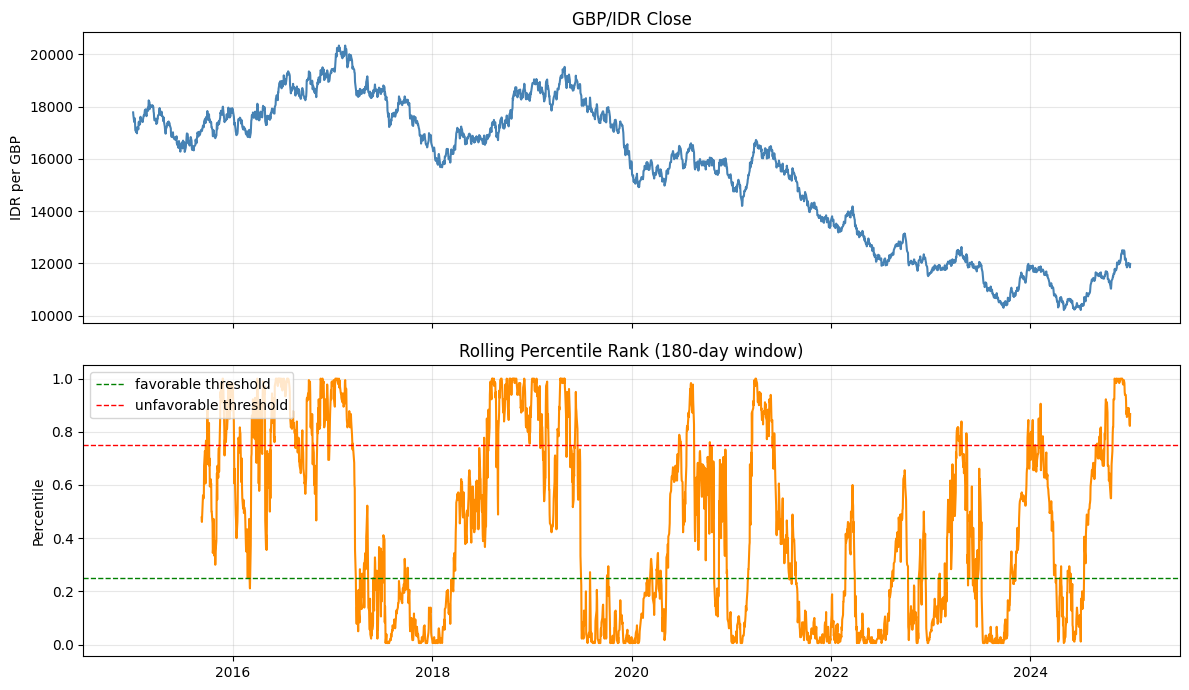

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7))

axes[0].plot(df.index, df["Close"], color="steelblue")
axes[0].set_title("GBP/IDR Close")
axes[0].set_ylabel("IDR per GBP")
axes[0].grid(True, alpha=0.3)

axes[1].plot(df.index, df["Percentile_Rank"], color="darkorange")
axes[1].axhline(0.25, color="green", linestyle="--", linewidth=1, label="favorable threshold")
axes[1].axhline(0.75, color="red", linestyle="--", linewidth=1, label="unfavorable threshold")
axes[1].set_title(f"Rolling Percentile Rank ({PERIOD}-day window)")
axes[1].set_ylabel("Percentile")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Classify into favorable / neutral / unfavorable

Thresholds match `config.yaml` (`percentile_favorable: 0.25`, `percentile_unfavorable: 0.75`).

In [ ]:
PCT_FAVORABLE = 0.25
PCT_UNFAVORABLE = 0.75

df["Value_Signal"] = df["Percentile_Rank"].apply(
    lambda p: classify_signal(p, favorable=PCT_FAVORABLE, unfavorable=PCT_UNFAVORABLE)
)
df["Value_Signal"].value_counts(dropna=False)


Value_Signal
Favorable      972
Neutral        842
Unfavorable    617
NaN            179
Name: count, dtype: int64

## 6. Eyeball a handful of "Favorable" days

Gut-check, not a rigorous test — do these dates look like plausible periods of
GBP weakness / IDR strength?

In [ ]:
df[df["Value_Signal"] == "Favorable"][["Close", "Percentile_Rank"]].head(10)


,Close,Percentile_Rank
2016-02-25,16839.025358,0.250000
2016-03-03,16857.503102,0.238889
2016-03-04,16824.015099,0.211111
2017-03-27,18695.604363,0.250000
2017-03-28,18579.683354,0.150000
2017-03-29,18507.906505,0.111111
2017-03-30,18427.614190,0.077778
2017-03-31,18560.477193,0.138889
2017-04-03,18589.053926,0.172222
2017-04-04,18380.445489,0.050000


In [ ]:
df[df["Value_Signal"] == "Unfavorable"][["Close", "Percentile_Rank"]].head(10)


,Close,Percentile_Rank
2015-09-24,17544.549711,0.750000
2015-09-25,17597.980210,0.766667
2015-09-28,17558.772413,0.750000
2015-09-29,17634.754813,0.777778
2015-09-30,17831.569270,0.883333
2015-10-01,17648.513862,0.788889
2015-10-06,17707.782521,0.833333
2015-11-16,17578.310226,0.855556
2015-11-17,17769.940258,0.950000
2015-11-18,17734.452287,0.927778


## 7. Where today sits right now

The single most recent row — this is the number your eventual "run today"
dashboard (Week 6) will surface.

In [ ]:
latest = df.dropna(subset=["Percentile_Rank"]).iloc[-1]
print("Date:          ", latest.name.date())
print("Rate (GBPIDR): ", round(latest["Close"], 2))
print("Percentile:    ", round(latest["Percentile_Rank"], 3))
print("Z-score:       ", round(latest["Zscore"], 3))
print("Signal:        ", latest["Value_Signal"])


Date:           2025-01-01
Rate (GBPIDR):  11977.54
Percentile:     0.867
Z-score:        1.175
Signal:         Unfavorable


## Next steps

- **Week 3**: backtest this signal — see `03_backtest_rule_signal.ipynb`, which
  simulates "transfer whenever Favorable" vs naive baselines (always transfer
  immediately / random day) and compares average rate paid.
- Worth trying a second `PERIOD` (e.g. 60 days) side by side once the backtest
  is in place, to see which window size actually performs better historically
  — don't assume 180 is optimal just because it's the default.
